<a href="https://colab.research.google.com/github/nicolaselias7/Calculo_Numerico/blob/main/tarefaGaussCN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa — Método de Gauss-Seidel

Implementação das questões 5, 6 e 7.

Sistema:

$$10x-y+2z=6$$
$$-x+11y-z=22$$
$$2x-y+10z=-10$$

Aproximação inicial: $x^{(0)}=(0,0,0)$ e tolerância $10^{-5}$.

Número de iterações: 6
Solução aproximada: x = 1.0000000269, y = 1.9999999762, z = -1.0000000078
Erro final: 1.2626069386e-06

 k    x^(k)    y^(k)     z^(k)  Erro infinito
 1 0.600000 2.054545 -0.914545       2.054545
 2 0.988364 2.006711 -0.997002       0.388364
 3 1.000071 2.000279 -0.999986       0.011708
 4 1.000025 2.000004 -1.000005       0.000276
 5 1.000001 2.000000 -1.000000       0.000024
 6 1.000000 2.000000 -1.000000       0.000001


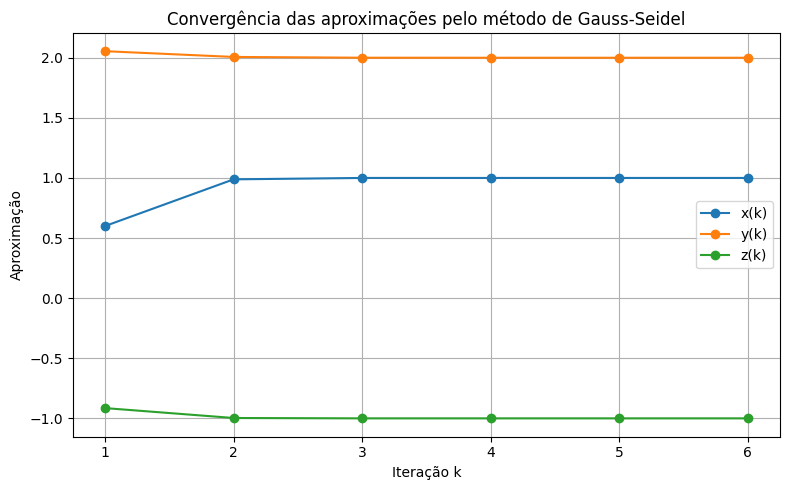

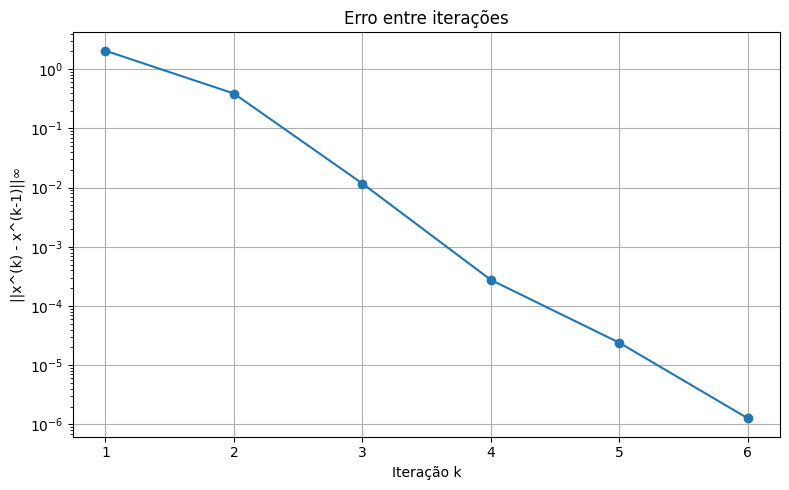

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Método de Gauss-Seidel
#
# Sistema:
# 10x - y + 2z = 6
# -x + 11y - z = 22
# 2x - y + 10z = -10
#
# Fórmulas iterativas:
# x = (6 + y - 2z) / 10
# y = (22 + x + z) / 11
# z = (-10 - 2x + y) / 10
# ------------------------------------------------------------

tol = 1e-5
x, y, z = 0.0, 0.0, 0.0

resultados = []
k = 0

while True:
    k += 1

    # Guarda os valores da iteração anterior
    x_ant, y_ant, z_ant = x, y, z

    # Gauss-Seidel: os valores recém-calculados são usados imediatamente
    x = (6 + y_ant - 2*z_ant) / 10
    y = (22 + x + z_ant) / 11
    z = (-10 - 2*x + y) / 10

    # Norma infinito da diferença entre duas iterações consecutivas
    erro = max(
        abs(x - x_ant),
        abs(y - y_ant),
        abs(z - z_ant)
    )

    resultados.append([k, x, y, z, erro])

    if erro < tol:
        break

# Tabela solicitada
df = pd.DataFrame(
    resultados,
    columns=["k", "x^(k)", "y^(k)", "z^(k)", "Erro infinito"]
)

print("Número de iterações:", k)
print(f"Solução aproximada: x = {x:.10f}, y = {y:.10f}, z = {z:.10f}")
print(f"Erro final: {erro:.10e}")
print()
print(df.to_string(index=False))

# ------------------------------------------------------------
# Gráfico 1: x(k), y(k) e z(k) em função de k
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.plot(df["k"], df["x^(k)"], marker="o", label="x(k)")
plt.plot(df["k"], df["y^(k)"], marker="o", label="y(k)")
plt.plot(df["k"], df["z^(k)"], marker="o", label="z(k)")
plt.xlabel("Iteração k")
plt.ylabel("Aproximação")
plt.title("Convergência das aproximações pelo método de Gauss-Seidel")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Gráfico 2: erro entre iterações em escala logarítmica
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.semilogy(df["k"], df["Erro infinito"], marker="o")
plt.xlabel("Iteração k")
plt.ylabel("||x^(k) - x^(k-1)||∞")
plt.title("Erro entre iterações")
plt.grid(True)
plt.tight_layout()
plt.show()
